<a href="https://colab.research.google.com/github/mjcolebank/MATH328_UofSC/blob/main/Homework7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Homework 7
In this homework, we will look at 200 observations related to California home prices. The goal is to examine how regression models perform here.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(seed=223)
import csv


# California Housing

This notebook uses scikit-learn's California housing regression dataset. We have a subset of 200 observations, five real-valued features, and a continuous target representing median house value in units of $100,000.

Our goal is to relate the average number of bedrooms, average occupancy, average number of rooms, house age, and median income to predict the median house value in a given area of California

## NOTE: IF YOU ARE USING COLAB, YOU NEED TO UPLOAD THE CSV FILE
To do this, click on the folder icon to the left of this box, then drag the file 'california_housing_small.csv' from blackboard into the folder. It should automatically load the csv file into your available files.


In [ ]:
housing = pd.read_csv('california_housing_small.csv')
X_all = np.array([housing['AveBedrms'],housing['AveOccup'],housing['AveRooms'],housing['HouseAge'],housing['MedInc']]).T
y = np.array(housing['MedHouseVal'])
X_names = ['Average Bedrooms','Average Occupancy','Average # Rooms','Average House Age','Median Household Income']
y_names = ['Median House Value']

## Part A: Analyzing the data
The code below provides metrics of the measurements, as well as pairwise relationships.

Describe the data in terms of its statistical moments and in terms of the qualitative behavior.

In [ ]:
mean_X = np.mean(X_all,axis=0)
var_X  = np.var(X_all,axis=0)
mean_y = np.mean(y)
var_y = np.var(y)
print('X variables:\n')
for i in range(5):
    print(f'Variable: {X_names[i]},  Mean: {mean_X[i]},  Var: {var_X[i]}')

print('\n y variable:\n')
print(f'Variable: {y_names},  Mean: {mean_y},  Var: {var_y}')


X variables:

Variable: Average Bedrooms,  Mean: 1.0580680060666392,  Var: 0.017983891129122524
Variable: Average Occupancy,  Mean: 2.9876890855487908,  Var: 0.514819062584564
Variable: Average # Rooms,  Mean: 5.192182381511726,  Var: 1.7456463609060109
Variable: Average House Age,  Mean: 29.565,  Var: 139.935775
Variable: Median Household Income,  Mean: 3.7941599999999998,  Var: 3.6762659795

 y variable:

Variable: ['Median House Value'],  Mean: 2.0415503,  Var: 1.2224288225729099


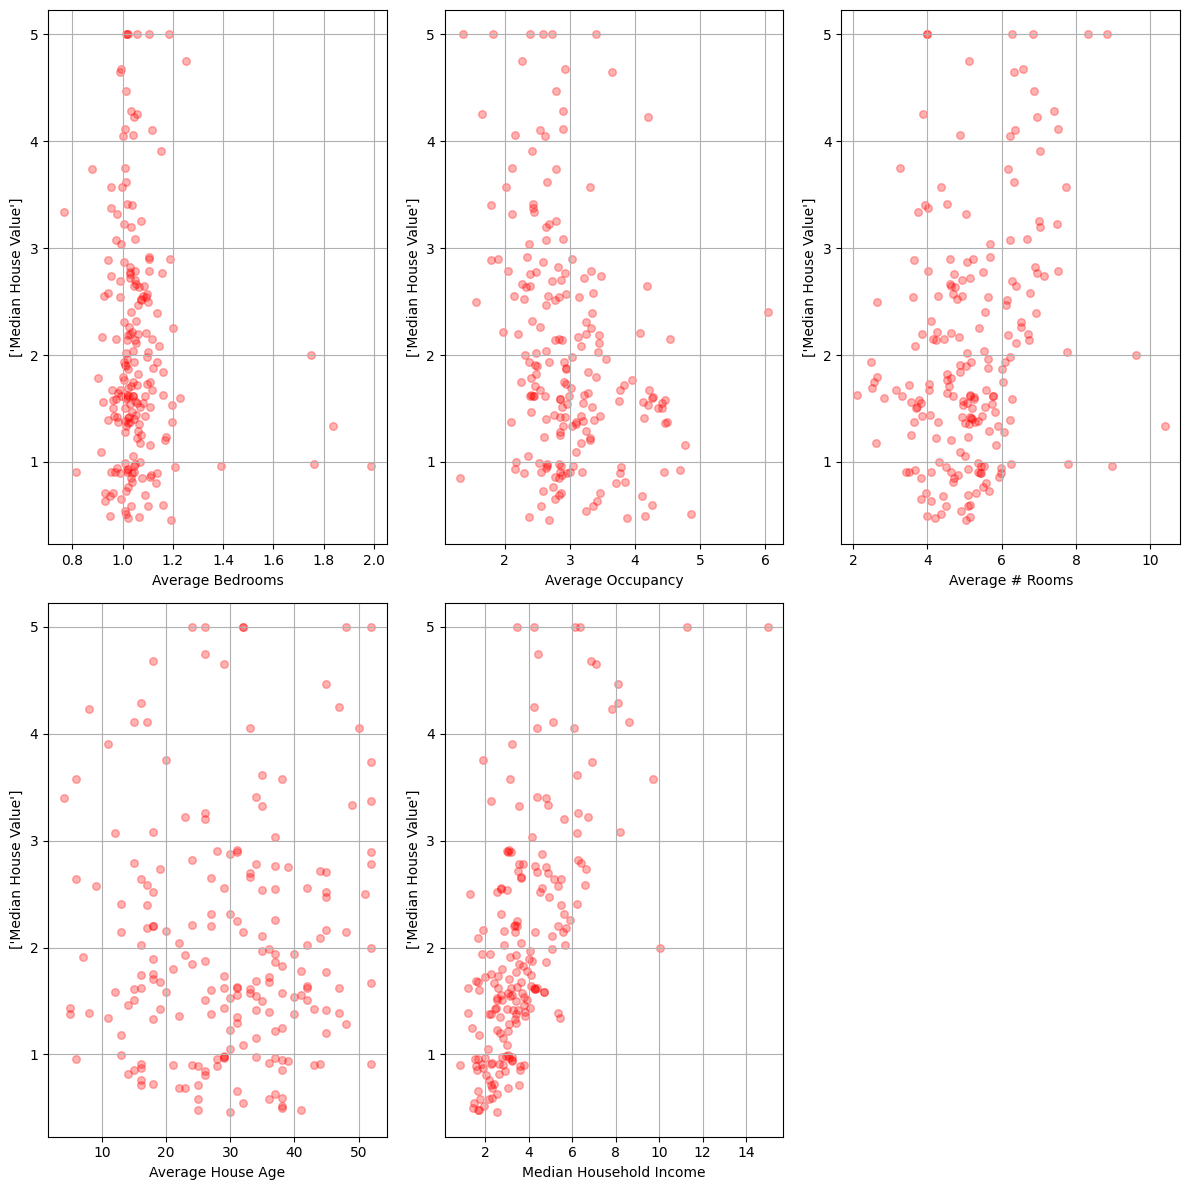

In [ ]:
plt.figure(figsize=(12,12))
for i in range(5):
    plt.subplot(2,3,i+1)
    plt.scatter(x=X_all[:,i],y=y,s=30,c='red',alpha=0.3)
    plt.xlabel(X_names[i])
    plt.ylabel(y_names)
    plt.grid()
plt.tight_layout()
plt.show()

## Part B: Testing regression models on median household income
The code below develops polynomial models to relate Median Household Income to Median Home price. We will use cross validation to test our models with 80% of the data used for training.

(i) Based on the data, what relationship seems likely between these two?
(ii) Use the polynomial models and training/testing SSE and coefficient of determinination to assess the models performance.
(iii) Compute the AIC and assess which model performs best.

In [ ]:
x_income = X_all[:, 4]
ids = rng.permutation(len(y))
n_train = int(0.8*len(y))
id_train, id_test = ids[:n_train], ids[n_train:]

def sse(y, yhat):
    return np.sum((y-yhat)**2)

def r2(y, yhat):
    return 1-sse(y,yhat)/np.sum((y-np.mean(y))**2)

def fit_least_squares(X, y):
    return np.linalg.lstsq(X,y,rcond=None)[0]

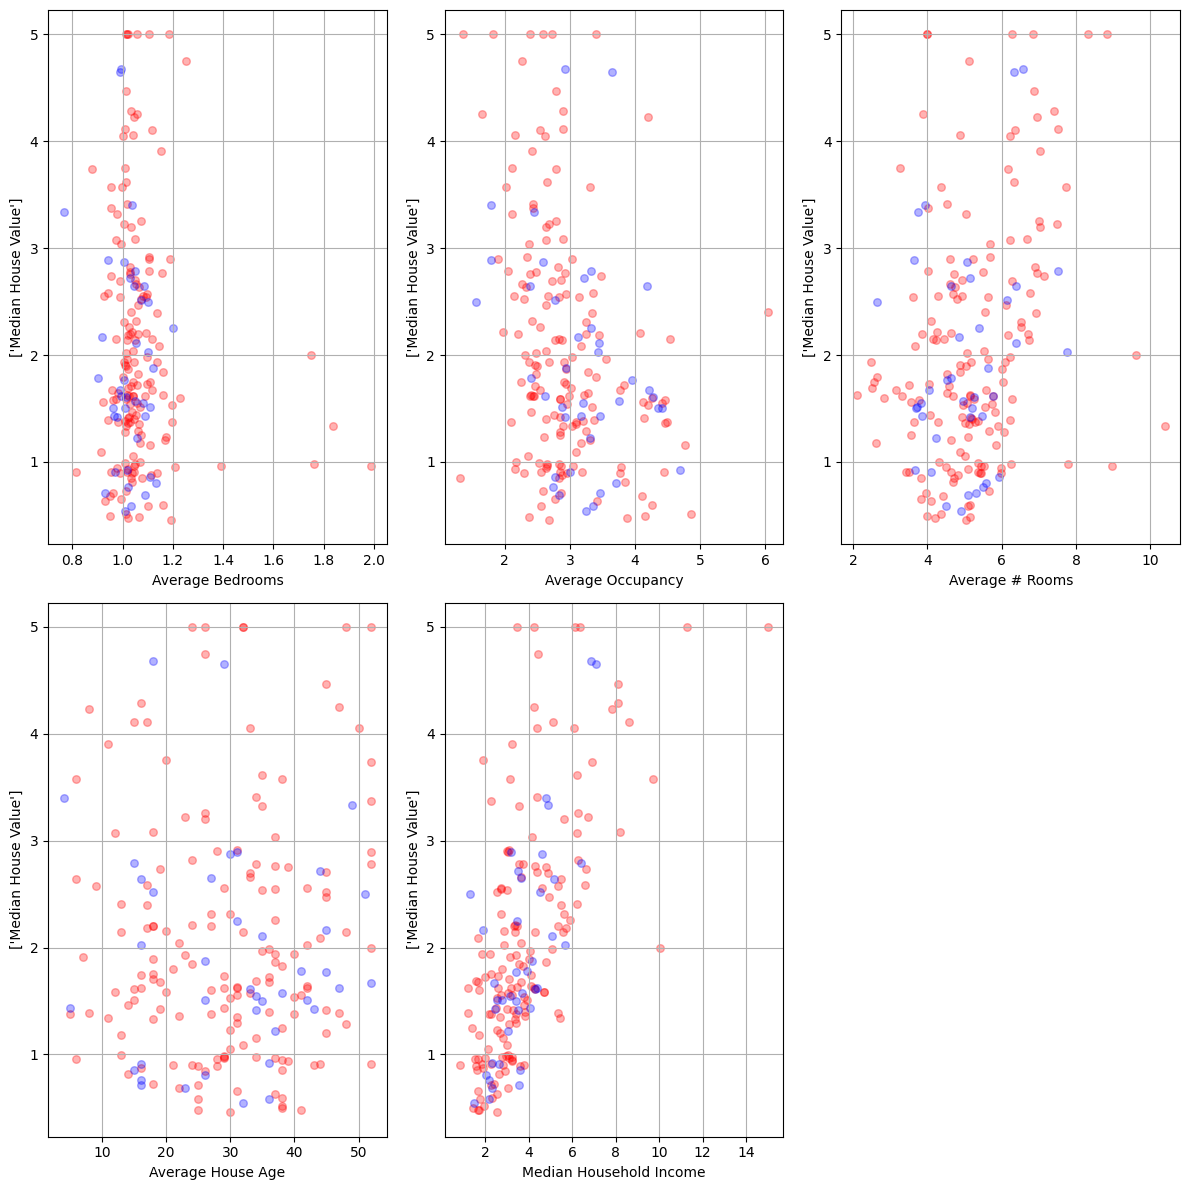

In [ ]:
# Plot the training vs testing data
plt.figure(figsize=(12,12))
for i in range(5):
    plt.subplot(2,3,i+1)
    plt.scatter(x=X_all[id_train,i],y=y[id_train],s=30,c='red',alpha=0.3,label='training')
    plt.scatter(x=X_all[id_test,i],y=y[id_test],s=30,c='blue',alpha=0.3,label='testing')
    plt.xlabel(X_names[i])
    plt.ylabel(y_names)
    plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
# Fit polynomials linear to x^5
orders=range(1,6)
results=[]
models={}
R2_train = []
R2_test  = []
for order in orders:
    X_train=np.c_[*[x_income[id_train]**p for p in range(order+1)]]
    X_test=np.c_[*[x_income[id_test]**p for p in range(order+1)]]
    theta=fit_least_squares(X_train,y[id_train])
    yhat_train,yhat_test=X_train@theta,X_test@theta
    models[order]=theta
    results.append([order,len(theta),sse(y[id_train],yhat_train),sse(y[id_test],yhat_test),r2(y[id_train],yhat_train),r2(y[id_test],yhat_test)])
    R2_train.append(r2(y[id_train],yhat_train))
    R2_test.append(r2(y[id_test],yhat_test))

results=pd.DataFrame(results,columns=['order','parameters','train_SSE','test_SSE','train_R2','test_R2'])
display(results)

,order,parameters,train_SSE,test_SSE,train_R2,test_R2
0,1,2,119.551079,20.987800,0.415509,0.463253
1,2,3,116.504173,20.899282,0.430406,0.465517
2,3,4,116.503308,20.935325,0.430410,0.464595
3,4,5,115.777847,20.012820,0.433957,0.488188
4,5,6,115.725123,20.064142,0.434215,0.486875


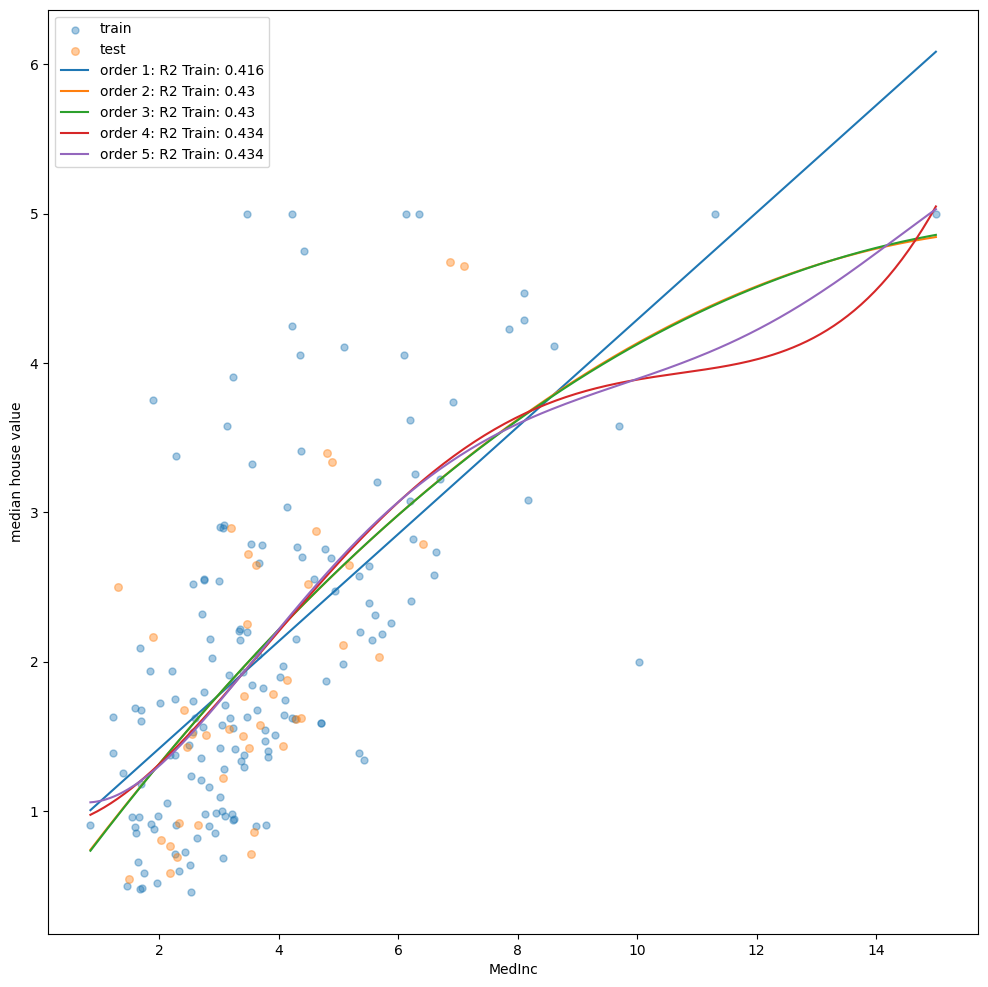

In [ ]:
income_plot=np.linspace(x_income.min(),x_income.max(),250).ravel()
plt.figure(figsize=(12,12))
plt.scatter(x_income[id_train],y[id_train],s=25,alpha=.40,label='train')
plt.scatter(x_income[id_test],y[id_test],s=30,alpha=0.40,label='test')
for order in orders:
    X_plot=np.c_[*[income_plot**p for p in range(order+1)]]
    plt.plot(income_plot,X_plot@models[order],label=f'order {order}: R2 Train: {round(R2_train[order-1],3)}')
plt.xlabel('MedInc'); plt.ylabel('median house value'); plt.legend(); plt.show()

In [ ]:
# Now assess the AIC
n=len(id_train)
results['AIC']=n*np.log(results.train_SSE/n)+2*results.parameters
display(results[['order','parameters','train_SSE','test_SSE','train_R2','test_R2','AIC']])
print('Best order by AIC:',int(results.loc[results.AIC.idxmin(),'order']))
print('Best order by testing SSE:',int(results.loc[results.test_SSE.idxmin(),'order']))

,order,parameters,train_SSE,test_SSE,train_R2,test_R2,AIC
0,1,2,119.551079,20.987800,0.415509,0.463253,-42.628816
1,2,3,116.504173,20.899282,0.430406,0.465517,-44.759475
2,3,4,116.503308,20.935325,0.430410,0.464595,-42.760664
3,4,5,115.777847,20.012820,0.433957,0.488188,-41.760092
4,5,6,115.725123,20.064142,0.434215,0.486875,-39.832970


Best order by AIC: 2
Best order by testing SSE: 4


## Part C: Multivariate linear regression

We now want to examine which models perform best when all the covariates are included.

We will ask the following:

(i) What is the train/test SSE when we include income only, income and number of rooms, and all data.

(ii) How do we interpret the parameters of these models, and how do they change when the model complexity changes?

(iii) What are the R2 values?

(iv) What are the AIC scores?

(v) Is there a definitive "best model"?

In [ ]:
# First define the data matrices
X_m1     = np.c_[np.ones(len(X_all)),X_all[:,4]]
X_m2     = np.c_[np.ones(len(X_all)),X_all[:,2],X_all[:,4]]
X_m3     = np.c_[np.ones(len(X_all)),X_all]

# Double check the sizes are correct
print('Sizes of the data matrices')
print(np.shape(X_m1))
print(np.shape(X_m2))
print(np.shape(X_m3))


Sizes of the data matrices
(200, 2)
(200, 3)
(200, 6)


In [ ]:
# Solve for the parameters using least squares
theta_m1     = fit_least_squares(X_m1[id_train,:],y[id_train])
theta_m2     = fit_least_squares(X_m2[id_train,:],y[id_train])
theta_m3     = fit_least_squares(X_m3[id_train,:],y[id_train])

print('model 1: input data is median income only')
print('parameters m1:',theta_m1)
print('model 2: input data is number of rooms and median income')
print('parameters m2:',theta_m2)
print('model 3: input data is average number of bedrooms, average occupancy, average number of rooms, house age, and median income')
print('parameters m3:',theta_m3)





model 1: input data is median income only
parameters m1: [0.6981 0.3591]
model 2: input data is number of rooms and median income
parameters m2: [ 1.4552 -0.2178  0.4591]
model 3: input data is average number of bedrooms, average occupancy, average number of rooms, house age, and median income
parameters m3: [ 1.8636  0.5246 -0.4137 -0.2485  0.0114  0.4785]


In [ ]:

# Predict on training and testing data
yhat_train_m1=X_m1[id_train,:]@theta_m1
yhat_test_m1=X_m1[id_test,:]@theta_m1

yhat_train_m2=X_m2[id_train,:]@theta_m2
yhat_test_m2=X_m2[id_test,:]@theta_m2

yhat_train_m3=X_m3[id_train,:]@theta_m3
yhat_test_m3=X_m3[id_test,:]@theta_m3

In [ ]:
# Calculate SSE, R2, and AIC for all models
sse_train_m1,sse_test_m1=sse(y[id_train],yhat_train_m1),sse(y[id_test],yhat_test_m1)
sse_train_m2,sse_test_m2=sse(y[id_train],yhat_train_m2),sse(y[id_test],yhat_test_m2)
sse_train_m3,sse_test_m3=sse(y[id_train],yhat_train_m3),sse(y[id_test],yhat_test_m3)

# n*np.log(results.train_SSE/n)+2*results.parameters
aic_m1= 2*len(theta_m1) + n*np.log(sse_train_m1/n)
aic_m2= 2*len(theta_m2) + n*np.log(sse_train_m2/n)
aic_m3= 2*len(theta_m3) + n*np.log(sse_train_m3/n)

r2_m1_train = r2(y[id_train],yhat_train_m1)
r2_m2_train = r2(y[id_train],yhat_train_m2)
r2_m3_train = r2(y[id_train],yhat_train_m3)

r2_m1_test = r2(y[id_test],yhat_test_m1)
r2_m2_test = r2(y[id_test],yhat_test_m2)
r2_m3_test = r2(y[id_test],yhat_test_m3)

print('Results for M1, M2, and M3:')
print(f'train SSE: {sse_train_m1:.4f}  {sse_train_m2:.4f}  {sse_train_m3:.4f}')
print(f'test SSE:  {sse_test_m1:.4f}  {sse_test_m2:.4f}  {sse_test_m3:.4f}')
print(f'train R^2: {r2_m1_train:.4f}  {r2_m2_train:.4f}  {r2_m3_train:.4f}')
print(f'test R^2:  {r2_m1_test:.4f}  {r2_m2_test:.4f}  {r2_m3_test:.4f}')
print(f'AIC:      {aic_m1:.4f}  {aic_m2:.4f}  {aic_m3:.4f}')

Results for M1, M2, and M3:
train SSE: 119.5511  111.8969  93.2453
test SSE:  20.9878  17.7293  14.3604
train R^2: 0.4155  0.4529  0.5441
test R^2:  0.4633  0.5466  0.6327
AIC:      -42.6288  -51.2154  -74.3905
